In [1]:
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)
from astropy.io import fits
from matplotlib import pyplot as plt
import numpy as np

In [2]:
#Abrimos el fits de las estrellas
star_1b = fits.open('Star1_B.fits')[0]
star_1v = fits.open('Star1_V.fits')[0]
star_2b = fits.open('Star2_B.fits')[0]
star_2v = fits.open('Star2_V.fits')[0]
#data y header
data = star_1b.data
header = star_1b.header
header


SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                  -32 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 4096                                                  
NAXIS2  =                 4096                                                  
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
OBSERVER= 'Cortes, Martinez, Soto' / SBIGFITSEXT The name of the observer       
ORIGIN  = 'MAS500  '           / Description of location                        
TELESCOP= 'MAS500  '           / SBIGFITSEXT The model Telescope                
FOCALLEN=                6500. / SBIGFITSEXT Telescope focal length in mm       
APTDIA  =                 500. / SBIGFITSEXT Aperture diameter in mm            
SBUUID  = '{860cfa7f-7142-46

In [3]:
#Threshold, para cada estrella
threshold_1b = detect_threshold(star_1b.data, nsigma = 5)
threshold_1v = detect_threshold(star_1v.data, nsigma = 5)
threshold_2b = detect_threshold(star_2b.data, nsigma = 5)
threshold_2v = detect_threshold(star_2v.data, nsigma = 5)
#Detectamos fuentes
sour_1b = detect_sources(star_1b.data, threshold_1b, npixels=50)
sour_1v = detect_sources(star_1v.data, threshold_1v, npixels=50)
sour_2b = detect_sources(star_2b.data, threshold_2b, npixels=50)
sour_2v = detect_sources(star_2v.data, threshold_2v, npixels=50)

In [6]:
# Generamos un mapa de colores para cada fuente
cmap_sour_1b = sour_1b.make_cmap(seed=123)
cmap_sour_1v = sour_1v.make_cmap(seed=123)
cmap_sour_2b = sour_2b.make_cmap(seed=123)
cmap_sour_2v = sour_2v.make_cmap(seed=123)


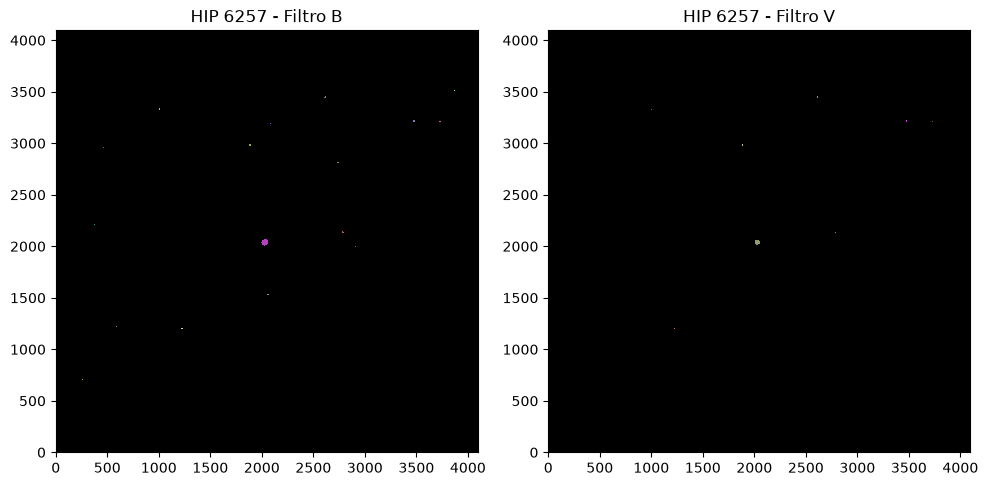

HIP 6257 - Filtro B:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 19
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
HIP 6257 - Filtro V:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 8
labels: [1 2 3 4 5 6 7 8]


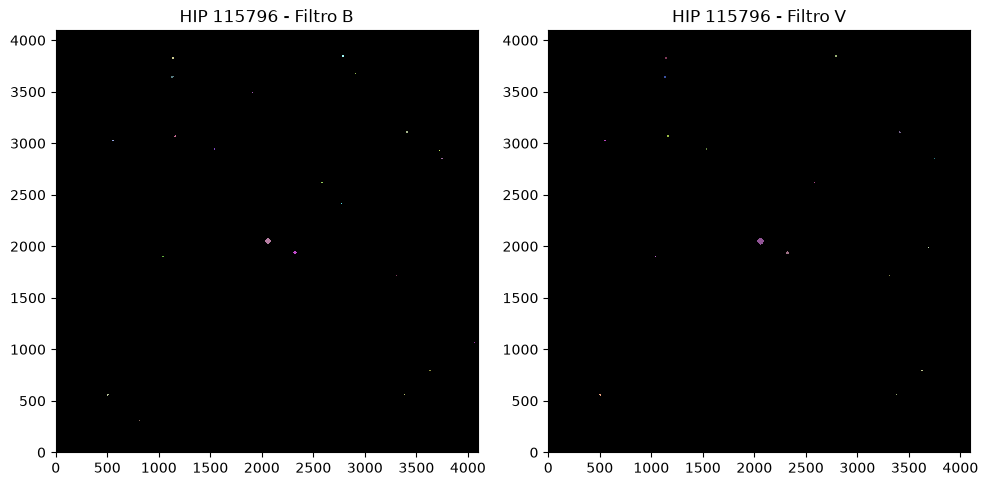

HIP 115796 - Filtro B:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 22
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
HIP 115796 - Filtro V:
<photutils.segmentation.core.SegmentationImage>
shape: (4096, 4096)
n_labels: 17
labels: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17]


In [8]:
# HIP 6257
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sour_1b, origin='lower', cmap=cmap_sour_1b, interpolation='nearest')
ax[0].set_title('HIP 6257 - Filtro B')

ax[1].imshow(sour_1v, origin='lower', cmap=cmap_sour_1v, interpolation='nearest')
ax[1].set_title('HIP 6257 - Filtro V')

plt.tight_layout()
plt.show()

print("HIP 6257 - Filtro B:")
print(sour_1b)
print("HIP 6257 - Filtro V:")
print(sour_1v)


# HIP 115796
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(sour_2b, origin='lower', cmap=cmap_sour_2b, interpolation='nearest')
ax[0].set_title('HIP 115796 - Filtro B')

ax[1].imshow(sour_2v, origin='lower', cmap=cmap_sour_2v, interpolation='nearest')
ax[1].set_title('HIP 115796 - Filtro V')

plt.tight_layout()
plt.show()

print("HIP 115796 - Filtro B:")
print(sour_2b)
print("HIP 115796 - Filtro V:")
print(sour_2v)
plt.show()

In [9]:
#Obtenemos el catálogo de la primera
cat_1b = SourceCatalog(data, sour_1b)
#Lo pasamos a tabla y lo mostramos
tbl_1b = cat_1b.to_table()
tbl_1b

label,x_centroid,y_centroid,sky_centroid,bbox_xmin,bbox_xmax,bbox_ymin,bbox_ymax,area,semimajor_axis,semiminor_axis,orientation,eccentricity,min_value,max_value,segment_flux,segment_flux_err,kron_flux,kron_flux_err,flags
,,,,,,,,pix2,pix,pix,deg,,,,,,,,
int32,float64,float64,object,int64,int64,int64,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,int64
1,1022.9410729887342,263.4717115602225,None,1018,1029,259,268,73.0,2.89048995837343,2.2390773278533587,-3.353839233184743,0.6324074654266915,55.69702911376953,94.5172348022461,4590.829875946045,nan,66340.63733831495,nan,0
2,259.96970611463234,708.7105563739889,None,254,266,704,714,97.0,3.018058738701323,2.543166948857148,6.227345619832421,0.538461805144006,55.64982986450195,92.07261657714844,6493.810020446777,nan,76782.03218694689,nan,0
3,1226.0537187480345,1205.8308285973592,None,1219,1233,1200,1213,142.0,3.4953058110669377,3.0456355325047504,1.5513491196563123,0.4906615652745327,55.91678237915039,100.50926971435547,10335.58572769165,nan,100432.79010611596,nan,0
4,590.2399017883228,1223.3746694041372,None,584,598,1217,1230,135.0,3.329656057259239,3.0625357218409466,9.774509006219356,0.3924451797738174,55.71051788330078,101.97660827636719,9812.25456237793,nan,99600.08493889788,nan,0
5,2059.610110364538,1529.9735754145286,None,2052,2066,1522,1537,154.0,3.430760814549944,3.32115666644761,-2.983682907115202,0.25074750326217743,55.807796478271484,112.47320556640625,11525.81430053711,nan,105421.36686017293,nan,0
6,960.5799897832649,1730.00230683765,None,955,966,1724,1735,85.0,2.865824232123532,2.431336248002439,-25.610017633702427,0.5293719187136076,55.89674758911133,88.07966613769531,5766.536510467529,nan,67566.1093869877,nan,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14,2086.1652408828145,3194.578448884238,None,2080,2092,3190,3200,90.0,2.888291717387062,2.4661445607480044,-14.812016842533861,0.5205323876876471,55.880157470703125,86.82811737060547,6156.1049880981445,nan,66260.49997235349,nan,0


In [10]:
#Catalogo de las 4
# Catálogo para HIP117678 
cat_1b = SourceCatalog(star_1b.data, sour_1b)
cat_1v = SourceCatalog(star_1v.data, sour_1v)
# Catálogo para HIP116375  
cat_2b = SourceCatalog(star_2b.data, sour_2b)
cat_2v = SourceCatalog(star_2v.data, sour_2v)

#Lo pasamos a tabla y lo mostramos
tbl_1b = cat_1b.to_table()
tbl_1v = cat_1v.to_table()
tbl_2b = cat_2b.to_table()
tbl_2v = cat_2v.to_table()

print(tbl_1b)
print(tbl_1v)
print(tbl_2b)
print(tbl_2v)

label     x_centroid     ... kron_flux_err flags
                         ...                    
----- ------------------ ... ------------- -----
    1 1022.9410729887342 ...           nan     0
    2 259.96970611463234 ...           nan     0
    3 1226.0537187480345 ...           nan     0
    4  590.2399017883228 ...           nan     0
    5  2059.610110364538 ...           nan     0
    6  960.5799897832649 ...           nan     0
  ...                ... ...           ...   ...
   13 1886.8970473988759 ...           nan     0
   14 2086.1652408828145 ...           nan     0
   15 3480.0166753749063 ...           nan     0
   16 3728.2458897860106 ...           nan     0
   17 1005.9438655473012 ...           nan     0
   18 2615.4910019676336 ...           nan     0
   19 3874.3929765166886 ...           nan     0
Length = 19 rows
label     x_centroid     ... kron_flux_err flags
                         ...                    
----- ------------------ ... ------------- -----
   

In [11]:
# Ahora extraemos las columnas
tabla_1b = tbl_1b['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_1v = tbl_1v['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_2b = tbl_2b['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
tabla_2v = tbl_2v['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux']
print(tabla_1b)
print(tabla_1v)
print(tabla_2b)
print(tabla_2v)

label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1 1022.9410729887342 ...  4590.829875946045
    2 259.96970611463234 ...  6493.810020446777
    3 1226.0537187480345 ...  10335.58572769165
    4  590.2399017883228 ...   9812.25456237793
    5  2059.610110364538 ...  11525.81430053711
    6  960.5799897832649 ...  5766.536510467529
  ...                ... ...                ...
   13 1886.8970473988759 ...  34461.96158981323
   14 2086.1652408828145 ... 6156.1049880981445
   15 3480.0166753749063 ...  70432.91973114014
   16 3728.2458897860106 ... 12181.313068389893
   17 1005.9438655473012 ...  21407.10842514038
   18 2615.4910019676336 ...  28568.03448486328
   19 3874.3929765166886 ...  8765.749992370605
Length = 19 rows
label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1  1226.12198624518

In [12]:
#obtenemos flujo real
tabla_1b['segment_flux'] = tabla_1b['segment_flux']/header['EXPTIME']
tabla_1v['segment_flux'] = tabla_1v['segment_flux']/header['EXPTIME']
tabla_2b['segment_flux'] = tabla_2b['segment_flux']/header['EXPTIME']
tabla_2v['segment_flux'] = tabla_2v['segment_flux']/header['EXPTIME']
#mostamos
print(tabla_1b)
print(tabla_1v)
print(tabla_2b)
print(tabla_2v)

label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1 1022.9410729887342 ...  65.58328394208635
    2 259.96970611463234 ...  92.76871457781111
    3 1226.0537187480345 ...  147.6512246813093
    4  590.2399017883228 ... 140.17506517682756
    5  2059.610110364538 ...   164.654490007673
    6  960.5799897832649 ...  82.37909300667899
  ...                ... ...                ...
   13 1886.8970473988759 ...  492.3137369973319
   14 2086.1652408828145 ...  87.94435697283063
   15 3480.0166753749063 ... 1006.1845675877163
   16 3728.2458897860106 ... 174.01875811985562
   17 1005.9438655473012 ...  305.8158346448626
   18 2615.4910019676336 ... 408.11477835518974
   19 3874.3929765166886 ... 125.22499989100865
Length = 19 rows
label     x_centroid     ...    segment_flux   
                         ...                   
----- ------------------ ... ------------------
    1  1226.12198624518

In [18]:
#Buscamos la fuente que es la estrella (mayor área)
star_1b_index = np.argmax(tabla_1b['area']) 
star_1v_index = np.argmax(tabla_1v['area']) 
star_2b_index = np.argmax(tabla_2b['area']) 
star_2v_index = np.argmax(tabla_2v['area'])
#Magnitud calibrada
tabla_1b['magnitude'] = zp_mean_b - 2.5 * np.log(tabla_1b['segment_flux'])
tabla_1v['magnitude'] = zp_mean_v - 2.5 * np.log(tabla_1v['segment_flux'])
tabla_2b['magnitude'] = zp_mean_b - 2.5 * np.log(tabla_2b['segment_flux'])
tabla_2v['magnitude'] = zp_mean_v - 2.5 * np.log(tabla_2v['segment_flux'])

print(tabla_1b)
print(tabla_1v)
print(tabla_2b)
print(tabla_2v)
#Obtenemos flujo
flux_star_1b = tabla_1b['segment_flux'][star_1b_index]
flux_star_1v = tabla_1v['segment_flux'][star_1v_index]
flux_star_2b = tabla_2b['segment_flux'][star_2b_index]
flux_star_2v = tabla_2v['segment_flux'][star_2v_index]

#Magnitud media
mag_1b = -2.5 * np.log(flux_star_1b)
mag_1v = -2.5 * np.log(flux_star_1v)
mag_2b = -2.5 * np.log(flux_star_2b)
mag_2v = -2.5 * np.log(flux_star_2v)

#Zeropoint (depende del filtro y la estrella)
zp_1b =  7.486	 - mag_1b
zp_1v =  7.439 - mag_1v
zp_2b =  7.710 - mag_2b
zp_2v =  7.450 - mag_2v

zp_mean_b = (zp_1b + zp_2b)/2
zp_mean_v = (zp_1v + zp_2v)/2

print(zp_mean_b,zp_mean_v)

label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1 1022.9410729887342 ... 16.348604472235046
    2 259.96970611463234 ... 15.481632947146965
    3 1226.0537187480345 ... 14.319774329429649
    4  590.2399017883228 ... 14.449676318598156
    5  2059.610110364538 ... 14.047283389881745
    6  960.5799897832649 ... 15.778577388354801
  ...                ... ...                ...
   13 1886.8970473988759 ... 11.309116110824423
   14 2086.1652408828145 ... 15.615145817639066
   15 3480.0166753749063 ...  9.522104584494357
   16 3728.2458897860106 ... 13.908998839314915
   17 1005.9438655473012 ... 12.499448903032057
   18 2615.4910019676336 ...  11.77803545019296
   19 3874.3929765166886 ... 14.731626290107833
Length = 19 rows
label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1  1226.12198624518

In [21]:
# Mostrar Zero Point por estrella y filtro
# Obtener flujo de cada estrella
flux_star_1b = tabla_1b['segment_flux'][star_1b_index]
flux_star_1v = tabla_1v['segment_flux'][star_1v_index]
flux_star_2b = tabla_2b['segment_flux'][star_2b_index]
flux_star_2v = tabla_2v['segment_flux'][star_2v_index]

# Magnitudes instrumentales
mag_1b = -2.5 * np.log10(flux_star_1b)
mag_1v = -2.5 * np.log10(flux_star_1v)
mag_2b = -2.5 * np.log10(flux_star_2b)
mag_2v = -2.5 * np.log10(flux_star_2v)

# Zero Point por estrella y filtro
zp_1b = 8.290 - mag_1b
zp_1v = 7.160 - mag_1v
zp_2b = 8.453 - mag_2b
zp_2v = 7.191 - mag_2v

# Zero Point promedio
zp_mean_b = (zp_1b + zp_2b) / 2
zp_mean_v = (zp_1v + zp_2v) / 2

print(zp_mean_b,zp_mean_v)

19.94171587045861 18.681884499888408


In [22]:
#Magnitud calibrada
tabla_1b['magnitude'] = zp_mean_b - 2.5 * np.log(tabla_1b['segment_flux'])
tabla_1v['magnitude'] = zp_mean_v - 2.5 * np.log(tabla_1v['segment_flux'])
tabla_2b['magnitude'] = zp_mean_b - 2.5 * np.log(tabla_2b['segment_flux'])
tabla_2v['magnitude'] = zp_mean_v - 2.5 * np.log(tabla_2v['segment_flux'])

print(tabla_1b)
print(tabla_1v)
print(tabla_2b)
print(tabla_2v)

label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1 1022.9410729887342 ...  9.483413756652531
    2 259.96970611463234 ...   8.61644223156445
    3 1226.0537187480345 ...  7.454583613847134
    4  590.2399017883228 ...  7.584485603015642
    5  2059.610110364538 ...  7.182092674299231
    6  960.5799897832649 ...  8.913386672772287
  ...                ... ...                ...
   13 1886.8970473988759 ...  4.443925395241909
   14 2086.1652408828145 ...  8.749955102056552
   15 3480.0166753749063 ... 2.6569138689118432
   16 3728.2458897860106 ...  7.043808123732401
   17 1005.9438655473012 ...  5.634258187449543
   18 2615.4910019676336 ...  4.912844734610445
   19 3874.3929765166886 ...  7.866435574525319
Length = 19 rows
label     x_centroid     ...     magnitude     
                         ...                   
----- ------------------ ... ------------------
    1  1226.12198624518